In [8]:
import numpy as np
from random import choices
import math
import matplotlib.pyplot as plt
import itertools
import scipy as sp

## Helpful Functions

First we create our initial population with $N$ individuals, where each of these
individuals is represented by a binary genome consisting of $n$ loci.
We create a list of N (uniformly) randomly generated n-tuples.

In [12]:
def init_pop(indiv_num, loci_num, space):
    pop_list = []
    if space == 'genotype':
        for i in range(indiv_num):
            pop_list.append(np.random.choice([0,1], loci_num))
        return pop_list
    elif space == 'phenotype':
        for i in range(indiv_num):
            pop_list.append(np.random.binomial(loci_num, 1/2))
        return pop_list

The phenotype of an individual is the number of ones in its genome, 
$g=(g_1,\ldots, g_n)\in\{0,1\}^n$, which we can just determine by summing up the 
entire genome $z(g)=\sum_{i=1}^n g_i$.

In [26]:
def phenotype(individual):
    return sum(individual) 

We can either have neutral evolution (no selection) where each genotype has 
the same fitness, $\omega(g)=1$, or we can have evolution with selection. 
For this we use the classic directional selection formula
$$\omega(g) = \exp(\langle\beta,g\rangle)= e^{\sum_{i=1}^n\beta_i g_i},$$
where $\beta_i \sim \mathcal{N}(0, \sigma^2)$.

In [14]:
def fitness(genotype, selection_coefficient):
    return np.exp(np.inner(genotype, selection_coefficient))

In [ ]:
# this version is way to inefficient

# def pheno_fitness_bad(geno_length, selection_coeff):
#     pheno_fit_list = np.zeros(geno_length+1)
#     for genome in itertools.product([0, 1], repeat=geno_length):
#         pheno_fit_list[phenotype(genome)] += fitness(genome, selection_coeff)
#     for k, fit in enumerate(pheno_fit_list):
#         pheno_fit_list[k] = fit/ sp.special.binom(geno_length, k)
#     return pheno_fit_list

In [87]:
# !!AI assisted code!!
# num_samples=1000 is a good amount, more than that takes a long time
def pheno_fitness(geno_length, selection_coeff, num_samples=1000):
    pheno_fit_list = np.zeros(geno_length+1)
    rng = np.random.default_rng() # random number generator

    for k in range(geno_length + 1):
        # k=0 and k=geno_length there is only one possible genome
        if k == 0:
            pheno_fit_list[k] = fitness(np.zeros(geno_length, dtype=int), selection_coeff)
            continue # the continue means we go to k+1
        elif k == geno_length:
            pheno_fit_list[k] = fitness(np.ones(geno_length, dtype=int), selection_coeff)
            continue

        total_fit = 0.0
        # we take a genome that has k 1s so those that have phenotype k
        base_genome = np.array([1]*k + [0]*(geno_length - k))
        
        for _ in range(num_samples):
            # Randomly shuffle the k 1s across the genome to create different 
            # genotypes that all have the same phenotype
            sample_genome = rng.permutation(base_genome)
            # we then take the fitness of this random genotype and add it to
            # the running total of the fitness for this phenotype
            total_fit += fitness(sample_genome, selection_coeff)

        # we then divide by the number of samples we took
        # for small numbers this is exact but for larger genotypes and for the
        # phenotypes this will get less and less exact
        pheno_fit_list[k] = total_fit / num_samples
        
    return pheno_fit_list

In [86]:
select = np.random.normal(0, .01, 1000)

list = pheno_fitness(1000, select)

For each loci in the genotype the mutation rate gives us the probability that it will flip.
This means to deter 

In [131]:
def mutate(genotype, geno_length, rate):
    # first we randomly choose the loci on the genome that will be mutated according to the give rate
    mutate_list = np.random.choice([0,1], geno_length, p=[1-rate, rate])
    # adding this list to the genotype we get that in the places where mutation
    # should occur we have 1 if it was 0 (this is what we want) and 2 if it was 1 (should be 0)
    l = np.add(genotype,mutate_list)
    # in the last step we find all the 2s and replace them by 0s
    return np.where(l == 2, l*0, l)

In [135]:
def find_normal(geno_length, mutation_rate):
    mutation_diff = []
    for i in range(100_000):
        genome = np.random.choice([0,1], geno_length)
        new_genome = mutate(genome, geno_length, mutation_rate)
        mutation_diff.append(phenotype(genome)-phenotype(new_genome))

    list_max = max(mutation_diff)
    list_min = min(mutation_diff)

    _, ax = plt.subplots()
    plt.grid()
    ax.hist(mutation_diff, list_max-list_min+1, density=True)
    plt.show()

In [136]:
def find_mutation_dist(geno_length, mutation_rate):
    mutation_diff = []
    # genome = np.random.choice([0,1], geno_length)
    genome = np.zeros(1000)
    print(phenotype(genome))
    for i in range(100_000):
        new_genome = mutate(genome, geno_length, mutation_rate)
        mutation_diff.append(phenotype(new_genome))


    list_max = max(mutation_diff)
    list_min = min(mutation_diff)
    print(mutation_diff)
    print(list_max-list_min+1)

    _, ax = plt.subplots()
    plt.grid()
    ax.hist(mutation_diff, list_max-list_min+1, density=True)
    plt.show()

0.0
[476.0, 508.0, 522.0, 492.0, 524.0, 510.0, 507.0, 507.0, 511.0, 522.0, 476.0, 495.0, 480.0, 493.0, 479.0, 495.0, 519.0, 505.0, 474.0, 499.0, 525.0, 522.0, 487.0, 463.0, 478.0, 470.0, 496.0, 522.0, 483.0, 520.0, 510.0, 475.0, 516.0, 492.0, 509.0, 514.0, 491.0, 487.0, 493.0, 512.0, 498.0, 489.0, 519.0, 501.0, 505.0, 527.0, 510.0, 499.0, 517.0, 504.0, 506.0, 516.0, 514.0, 484.0, 500.0, 532.0, 486.0, 484.0, 504.0, 527.0, 488.0, 528.0, 479.0, 488.0, 489.0, 514.0, 518.0, 505.0, 513.0, 490.0, 481.0, 489.0, 483.0, 517.0, 495.0, 507.0, 511.0, 516.0, 538.0, 499.0, 492.0, 572.0, 503.0, 514.0, 524.0, 492.0, 485.0, 503.0, 488.0, 518.0, 497.0, 514.0, 500.0, 519.0, 510.0, 476.0, 517.0, 501.0, 516.0, 504.0, 527.0, 505.0, 526.0, 502.0, 513.0, 489.0, 535.0, 504.0, 505.0, 479.0, 522.0, 502.0, 521.0, 486.0, 517.0, 499.0, 468.0, 481.0, 508.0, 501.0, 486.0, 531.0, 488.0, 471.0, 475.0, 490.0, 474.0, 476.0, 473.0, 478.0, 505.0, 490.0, 485.0, 503.0, 490.0, 497.0, 505.0, 537.0, 498.0, 509.0, 482.0, 501.0, 4

TypeError: `bins` must be an integer, a string, or an array

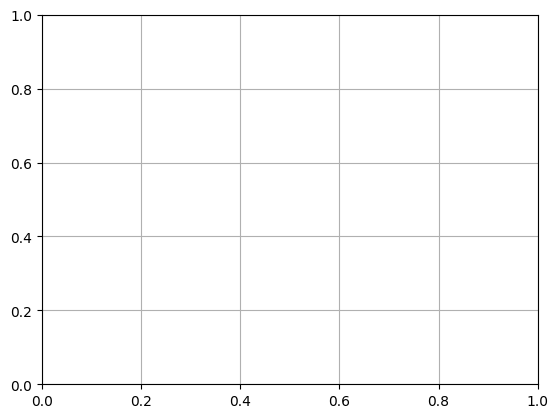

In [139]:
find_mutation_dist(1000, .5)

In [142]:
.78*4

3.12

In [143]:
3/4

0.75

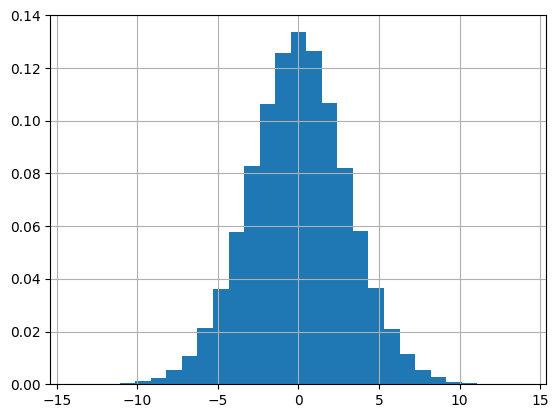

In [138]:
find_normal(1000, .01)

In [88]:
population = [[0,0,1], [1,1,0], [0,0,0]]
selection_coeff = np.random.normal(0, 1, 3)
pop_fitness = [fitness(geno, selection_coeff) for geno in population]
print(pop_fitness)
print(selection_coeff)

[0.21894484572030234, 0.670489128548662, 1.0]
[-0.18039691 -0.21935088 -1.51893543]


In [10]:
pop = [(0,1,0), (1,0,0), (1,1,1)]
l = [0.1,1,1.6]
choices(pop, weights=l, k=3)

[(1, 0, 0), (1, 0, 0), (1, 1, 1)]

## Wright Fisher Model

For the Wright-Fisher model I'm not completely sure how I should implement the evolution with selection.
I assume the idea is to make it such that individuals with a higher fitness (according to the classic directional selection formula) are more likely to be chosen.

In [ ]:
def wright_fisher(pop_size, geno_length, run_num, mutation_rate, variance, space='genotype', evolution='selection'):
    # first we define the selection pressure
    # if all selection coefficients are zero, all genotypes have equal fitness
    # for non-neutral selection we generate normally distributed selection coefficients
    if evolution == 'neutral':
        selection_coeff = np.zeros(geno_length)
    elif evolution == 'selection':
        selection_coeff = np.random.normal(0, variance, geno_length)
    else:
        raise ValueError("Evolution must either be 'neutral' or 'selection'")

    if space == 'genotype':
        # we initialize a population with 'pop_size' amount of 
        # individuals each having a genotype of length 'geno_length'
        population = init_pop(pop_size, geno_length, space)

        # average_fitness_list = []
        fitness_list = []
        for _ in range(run_num):
            # we calculate the fitness for each individual which gives us the weights for the selection
            pop_fitness = [fitness(geno, selection_coeff) for geno in population]
            fitness_list.append(pop_fitness)
            # the average fitness of the entire population in each generation
            # average_fitness_list.append(np.average(pop_fitness))
            
            # based on the fitness we choose the next population
            non_mutated_population = choices(population, weights=pop_fitness, k=pop_size)
            # we then mutate each individual according to the mutation rate
            for i, indiv in enumerate(non_mutated_population):
                population[i] = mutate(indiv, geno_length, mutation_rate) 
        # we have to calculate the fitness for the last generation seperatley       
        final_pop_fitness= [fitness(geno, selection_coeff) for geno in population]
        fitness_list.append(final_pop_fitness)
        # average_fitness_list.append(np.average(final_pop_fitness))
        return fitness_list

    elif space == 'phenotype':
        # we initialize a population of values in the phenotype space
        population = init_pop(pop_size, geno_length, space)
        average_fitness_pheno = pheno_fitness(geno_length, selection_coeff)

        pop_fitness = [average_fitness_pheno[pheno] for pheno in population]

        non_mutated_population = choices(population, weights=pop_fitness, k=pop_size)

        for i, indiv in enumerate(non_mutated_population):
            population[i] = np.random.binomial(geno_length, )
            


        


In [148]:
wright_fisher(1000, 1000, 100, .00001, .01)

<class 'numpy.ndarray'>


[[0.8627450040178778,
  1.070373929361041,
  1.018516365070488,
  0.7316277535987679,
  1.1152524916117224,
  0.8013225870981477,
  0.9198606371063527,
  1.027571560037912,
  0.7523120578020287,
  0.6915943364957257,
  0.8661128419252466,
  0.9712754962354803,
  0.949795490601555,
  0.9706786358383925,
  0.9119702095622934,
  0.8525056527328131,
  0.8434079499525159,
  1.0029531930276958,
  1.086794465799394,
  0.8020324275044884,
  1.0321317637239753,
  1.1070216507985522,
  1.0069814073156163,
  0.744811029620438,
  0.7927428367410708,
  0.7209131325558762,
  0.7554873274755373,
  0.8521351211890644,
  0.7684960999854321,
  1.2875305050679915,
  0.7632775630961822,
  1.0880668422576936,
  1.0858909083296857,
  0.8924913182587267,
  0.814674252006484,
  0.940502719231422,
  0.8878106826019496,
  0.9455990889707114,
  0.8833231747755553,
  1.0616428895240315,
  1.2303456454646489,
  1.0338560961920074,
  0.958541126992064,
  0.8905517390322294,
  0.9974269319204433,
  0.870496227961856

In [149]:
simulation_runs_selection = []
for x in range(100):
    run = wright_fisher(1000, 1000, 100, .00001, .01)
    simulation_runs_selection.append([run[0], run[-1]])

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.nd

In [ ]:
_, ax = plt.subplots()
#ax.set_title(f"Fitness over Time")
#ax.set_xlabel("Generation")
#ax.set_ylabel(f"Fitness")
# ax.set_ylim(0, 1e3)
plt.grid()

ax.hist

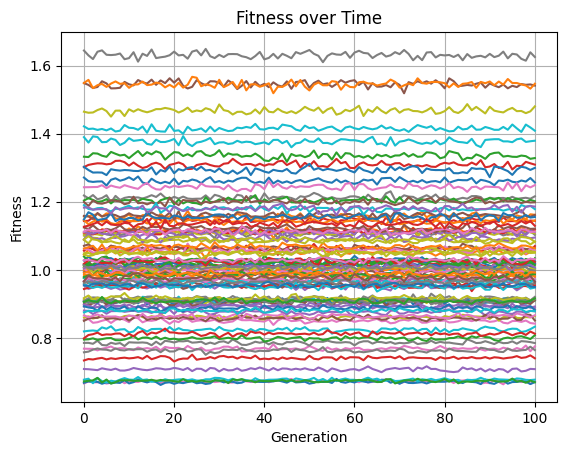

In [ ]:
_, ax = plt.subplots()
ax.set_title(f"Fitness over Time")
ax.set_xlabel("Generation")
ax.set_ylabel(f"Fitness")
# ax.set_ylim(0, 1e3)
plt.grid()

for result in simulation_runs_selection:
    ax.plot(np.arange(101), result)

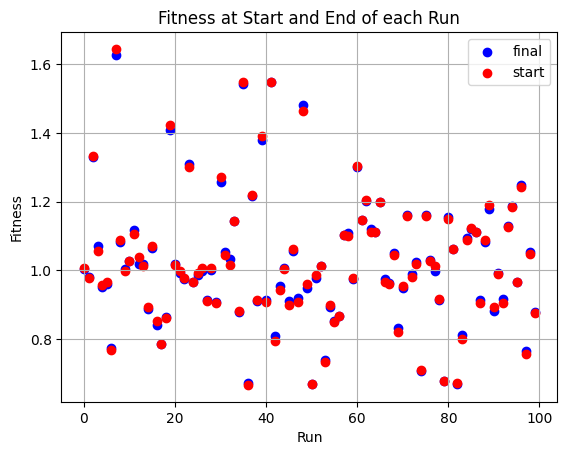

In [ ]:
_, ax = plt.subplots()
ax.set_title(f"Fitness at Start and End of each Run")
ax.set_xlabel("Run")
ax.set_ylabel(f"Fitness")
#ax.set_ylim(0, 1e21)
plt.grid()

first_fit = []
final_fit = []
for fit in simulation_runs_selection:
    final_fit.append(fit[-1])
    first_fit.append(fit[0])

ax.scatter(np.arange(100), final_fit, c='blue', label='final')
ax.scatter(np.arange(100), first_fit, c='red', label='start')
ax.legend()

NameError: name 'fitness_list' is not defined

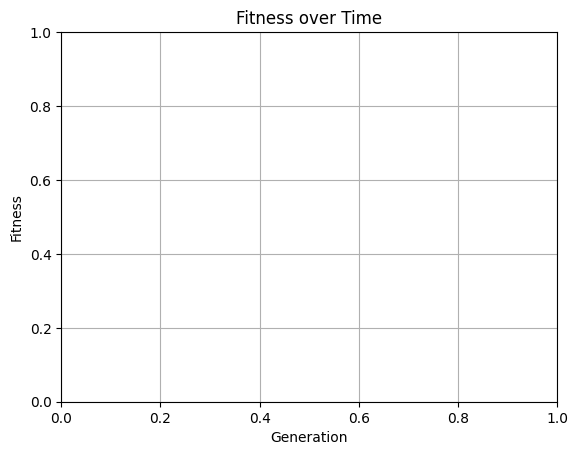

In [14]:
_, ax = plt.subplots()
ax.set_title(f"Fitness over Time")
ax.set_xlabel("Generation")
ax.set_ylabel(f"Fitness")
plt.grid()
# ax.set_ylim(100_000, 600_000)

ax.plot(np.arange(101), fitness_list)